# Grouping Pulse Events # 

This notebook works to: 



In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import matplotlib.colors as mcolors

import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import string
from tqdm import tqdm


/global/home/users/rubypercival/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/global/home/users/rubypercival/.local/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
file ='/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets/lowCF_filtered_merged_with_incdec_MCD12Q1mask_2024.parquet'
df = pd.read_parquet(file, engine='pyarrow')


In [3]:
df.head(7)

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,tz_name,datetime_utc,datetime_local,time_diff_hours,pulse_start,sm_surface,surface_temp,soil_temp_layer1,WFPS_c,dominant_texture,state_name,timezone,pre_slope,sm_class
0,36.05,-91.05,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaT,2024-02-29 18:00:00,NaN,False,0.188113,203.515932,204.294951,0.422821,sandy loam,Arkansas,America/Chicago,NaN,NaN
1,36.05,-91.05,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaT,2024-02-29 19:00:00,NaN,False,0.179144,202.797299,204.143615,0.402660,sandy loam,Arkansas,America/Chicago,NaN,NaN
2,36.05,-91.05,0.0,2024-03-01 02:00:00,NaN,NaN,NaN,NaT,2024-02-29 20:00:00,NaN,False,0.175506,202.309476,203.927366,0.394484,sandy loam,Arkansas,America/Chicago,NaN,NaN
3,36.05,-91.05,0.0,2024-03-01 03:00:00,NaN,NaN,NaN,NaT,2024-02-29 21:00:00,NaN,False,0.176829,202.036375,203.650729,0.397458,sandy loam,Arkansas,America/Chicago,NaN,NaN
4,36.05,-91.05,NaN,2024-03-01 04:00:00,NaN,NaN,NaN,NaT,2024-02-29 22:00:00,NaN,False,0.178152,201.763273,203.374092,0.400431,sandy loam,Arkansas,America/Chicago,NaN,NaN
5,36.05,-91.05,NaN,2024-03-01 05:00:00,NaN,NaN,NaN,NaT,2024-02-29 23:00:00,NaN,False,0.181154,201.555054,203.151193,0.407178,sandy loam,Arkansas,America/Chicago,NaN,NaN
6,36.05,-91.05,NaN,2024-03-01 06:00:00,NaN,NaN,NaN,NaT,2024-03-01 00:00:00,NaN,False,0.185717,201.407197,202.978285,0.417436,sandy loam,Arkansas,America/Chicago,NaN,NaN


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'tz_name', 'datetime_utc', 'datetime_local',
       'time_diff_hours', 'pulse_start', 'sm_surface', 'surface_temp',
       'soil_temp_layer1', 'WFPS_c', 'dominant_texture', 'state_name',
       'timezone', 'pre_slope', 'sm_class'],
      dtype='str')

# subset pulse starts

In [5]:
pulse_df = df[df["pulse_start"] == True].copy()

pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])
pulse_df = pulse_df.sort_values("datetime").reset_index(drop=True)
pulse_df["local_hour"] = pd.to_datetime(pulse_df["datetime_local"]).dt.hour

In [6]:
MIN_LOCAL_HOUR = 10  # exclude pulses that start before 10am local time

n_before = len(pulse_df)
pulse_df = pulse_df[pulse_df["local_hour"] >= MIN_LOCAL_HOUR].reset_index(drop=True)
print(f"dropped {n_before - len(pulse_df):,} pulses before {MIN_LOCAL_HOUR}:00 local "
      f"({len(pulse_df):,} / {n_before:,} remain)")

dropped 12,187 pulses before 10:00 local (4,396 / 16,583 remain)


In [7]:
spatial_degree = 0.2 #within ~20km 
time_hours = 24 #pulses within 1 day

In [8]:
pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

#time in hours since first pulse
pulse_df["time_num"] = (pulse_df["datetime"] - pulse_df["datetime"].min()).dt.total_seconds() / 3600

spatial_coords = pulse_df[["grid_lat", "grid_lon"]].to_numpy()
tree = cKDTree(spatial_coords)

candidate_pairs = tree.query_pairs(r=spatial_degree)
times = pulse_df["time_num"].to_numpy()
valid_pairs = [(i, j) for i, j in candidate_pairs if abs(times[i] - times[j]) <= time_hours]

n = len(pulse_df)
parent = np.arange(n)

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for i, j in valid_pairs:
    ri, rj = find(i), find(j)
    if ri != rj:
        parent[ri] = rj

pulse_df["group_id"] = [find(i) for i in range(n)]

In [9]:
pulse_df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'tz_name', 'datetime_utc', 'datetime_local',
       'time_diff_hours', 'pulse_start', 'sm_surface', 'surface_temp',
       'soil_temp_layer1', 'WFPS_c', 'dominant_texture', 'state_name',
       'timezone', 'pre_slope', 'sm_class', 'local_hour', 'time_num',
       'group_id'],
      dtype='str')

In [10]:
from pathlib import Path
output_file = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets/lowCF_grouped_2hour_pulses_MCD12Q1mask_2024_post10am.parquet'
Path(output_file).parent.mkdir(parents=True, exist_ok=True)
pulse_df.to_parquet(output_file, engine='pyarrow')
print('Saved to:', output_file)


Saved to: /global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets/lowCF_grouped_2hour_pulses_MCD12Q1mask_2024_post10am.parquet


# EDA

- finding events with precip before the pulse
- and no2 observations present for every day within the window

In [11]:
pre_pulse_days = 5      #how many days before the pulse to look for precip
post_pulse_days = 5     #how many days after the pulse must have NO2 obs
min_precip_mm = 2.0     #total precip (mm, summed over all cells x hours) needed in pre-window
min_event_cells = 3     #how big the event is
required_no2_days = post_pulse_days  #every one of the post-window days must have a NO2 reading
min_cells_per_day = 1   #at least this many cells with non-NaN NO2 on each post day
no2_pre_days = 5        #days before pulse that must have NO2 obs
no2_post_days = 5       #days after pulse that must have NO2 obs

In [12]:
#event metadata 
event_meta = (pulse_df.groupby("group_id").agg(
    n_cells= ("grid_lat", "count"),
    t0 = ("datetime", "min"),
    centroid_lat =("grid_lat", "mean"),
    centroid_lon = ("grid_lon", "mean")).reset_index())

#keep only events large enough
event_meta = event_meta[event_meta["n_cells"] >= min_event_cells].copy()
event_meta["t0"] = pd.to_datetime(event_meta["t0"])
event_meta["t0_date"] = event_meta["t0"].dt.normalize()

print(f"Candidate events (\u2265{min_event_cells} cells): {len(event_meta)}")

Candidate events (≥3 cells): 299


In [13]:
import gc
from pathlib import Path

relevant_pairs = list(set(zip(pulse_df['grid_lat'], pulse_df['grid_lon'])))
print(f'{len(relevant_pairs):,} unique grid cells to process')

temp_dir = Path('/global/scratch/users/rubypercival/temp_cell_chunks')
temp_dir.mkdir(exist_ok=True)

for lat, lon in tqdm(relevant_pairs, desc='writing per-cell files'):
    out_path = temp_dir / f'{lat}_{lon}.parquet'
    if out_path.exists():
        continue  # already written in a previous (possibly crashed) run -- skip it
    mask = (df['grid_lat'] == lat) & (df['grid_lon'] == lon)
    chunk = df[mask]
    chunk.to_parquet(out_path, engine='pyarrow')
    del chunk
    gc.collect()

print('Done writing all per-cell files')

def load_cell(lat, lon):
    path = temp_dir / f'{lat}_{lon}.parquet'
    if not path.exists():
        return None
    return pd.read_parquet(path, engine='pyarrow')

#score each event
records = []

for _, row in tqdm(event_meta.iterrows(), total=len(event_meta), desc='scoring events'):
    eid = row["group_id"]
    t0 = row["t0"]
    t0d = row["t0_date"]

    event_cells = (pulse_df[pulse_df["group_id"] == eid][["grid_lat", "grid_lon"]].drop_duplicates())

    cell_frames = [load_cell(lat, lon) for lat, lon in event_cells.itertuples(index=False)]
    cell_frames = [c for c in cell_frames if c is not None]
    if not cell_frames:
        continue
    sub = pd.concat(cell_frames, ignore_index=True)
    sub["date"] = sub["datetime"].dt.normalize()  # BUG FIX: needed by no2_window's filter below

#precipitation in previous days
    pre = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=pre_pulse_days)) & (sub["datetime"] <  t0)].copy()
    total_precip = pd.to_numeric(pre["h_precip_mm"], errors="coerce").sum()
    pre["date"] = pre["datetime"].dt.normalize()
    daily_precip = pre.groupby("date")["h_precip_mm"].apply(
        lambda x: pd.to_numeric(x, errors="coerce").sum())
    n_precip_days = (daily_precip > 0.1).sum()

    #want no2 for every day
    no2_window = sub[(sub["date"] >=t0d - pd.Timedelta(days=no2_pre_days)) &
    (sub["date"] <=t0d + pd.Timedelta(days=no2_post_days)) &
    (sub["date"] !=t0d)   #want toexclude the pulse day itself
    ].copy()

    daily_no2_cells = (no2_window.groupby("date")["no2_mean"].apply(lambda x: x.notna().sum()))

    expected_dates = pd.date_range(t0d - pd.Timedelta(days=no2_pre_days), 
                                   t0d + pd.Timedelta(days=no2_post_days), freq="D").normalize()
    expected_dates =expected_dates[expected_dates !=t0d]

    covered_dates= set(daily_no2_cells[daily_no2_cells >= min_cells_per_day].index.normalize())
    all_days_covered =set(expected_dates).issubset(covered_dates)

    days_with_no2 =(daily_no2_cells >=min_cells_per_day).sum()

    records.append({
        "group_id": eid,
        "n_cells": row["n_cells"],
        "t0": t0,
        "centroid_lat": row["centroid_lat"],
        "centroid_lon": row["centroid_lon"],
        "total_precip_mm": round(total_precip, 2),
        "n_precip_days": int(n_precip_days),
        "days_with_no2": int(days_with_no2),
        "all_days_covered": all_days_covered})

scored = pd.DataFrame(records)

3,477 unique grid cells to process


writing per-cell files: 100%|██████████| 3477/3477 [00:00<00:00, 6384.85it/s]


Done writing all per-cell files


scoring events: 100%|██████████| 299/299 [00:27<00:00, 10.93it/s]


In [14]:
#applyingtwo main filters
exemplars = scored[(scored["total_precip_mm"] >= min_precip_mm) & (scored["all_days_covered"] ==True)].copy()

exemplars = exemplars.sort_values(["total_precip_mm", "n_cells"], ascending=False).reset_index(drop=True)

print(f"\nNumber of exemplar events found: {len(exemplars)}")
print(f" (precip ≥ {min_precip_mm} mm in {pre_pulse_days} pre-days  AND  NO2 on all {no2_pre_days} pre + {no2_post_days} post days)\n")

print(exemplars[[ "group_id", "t0", "n_cells", "centroid_lat", "centroid_lon", 
                 "total_precip_mm", "n_precip_days", "days_with_no2"]].to_string(index=False))


Number of exemplar events found: 20
 (precip ≥ 2.0 mm in 5 pre-days  AND  NO2 on all 5 pre + 5 post days)

 group_id                  t0  n_cells  centroid_lat  centroid_lon  total_precip_mm  n_precip_days  days_with_no2
     2973 2024-05-08 15:00:00       13     44.680769    -93.750000       179.440002              6             10
     2571 2024-04-25 14:00:00       21     39.807143    -83.450000       149.649994              5             10
      159 2024-03-15 15:00:00       86     40.874419    -87.843023       107.470001              3             10
     2093 2024-04-16 19:00:00        5     43.130000    -95.650000        96.040001              5             10
     3059 2024-05-13 18:00:00       65     48.114615   -101.406923        95.339996              6             10
     1452 2024-04-08 18:00:00       22     41.763636    -92.995455        84.720001              4             10
     2986 2024-05-08 16:00:00        6     44.783333    -94.200000        76.540001           

/tmp/ipykernel_3033664/3918270060.py:217: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 1, 0.99])


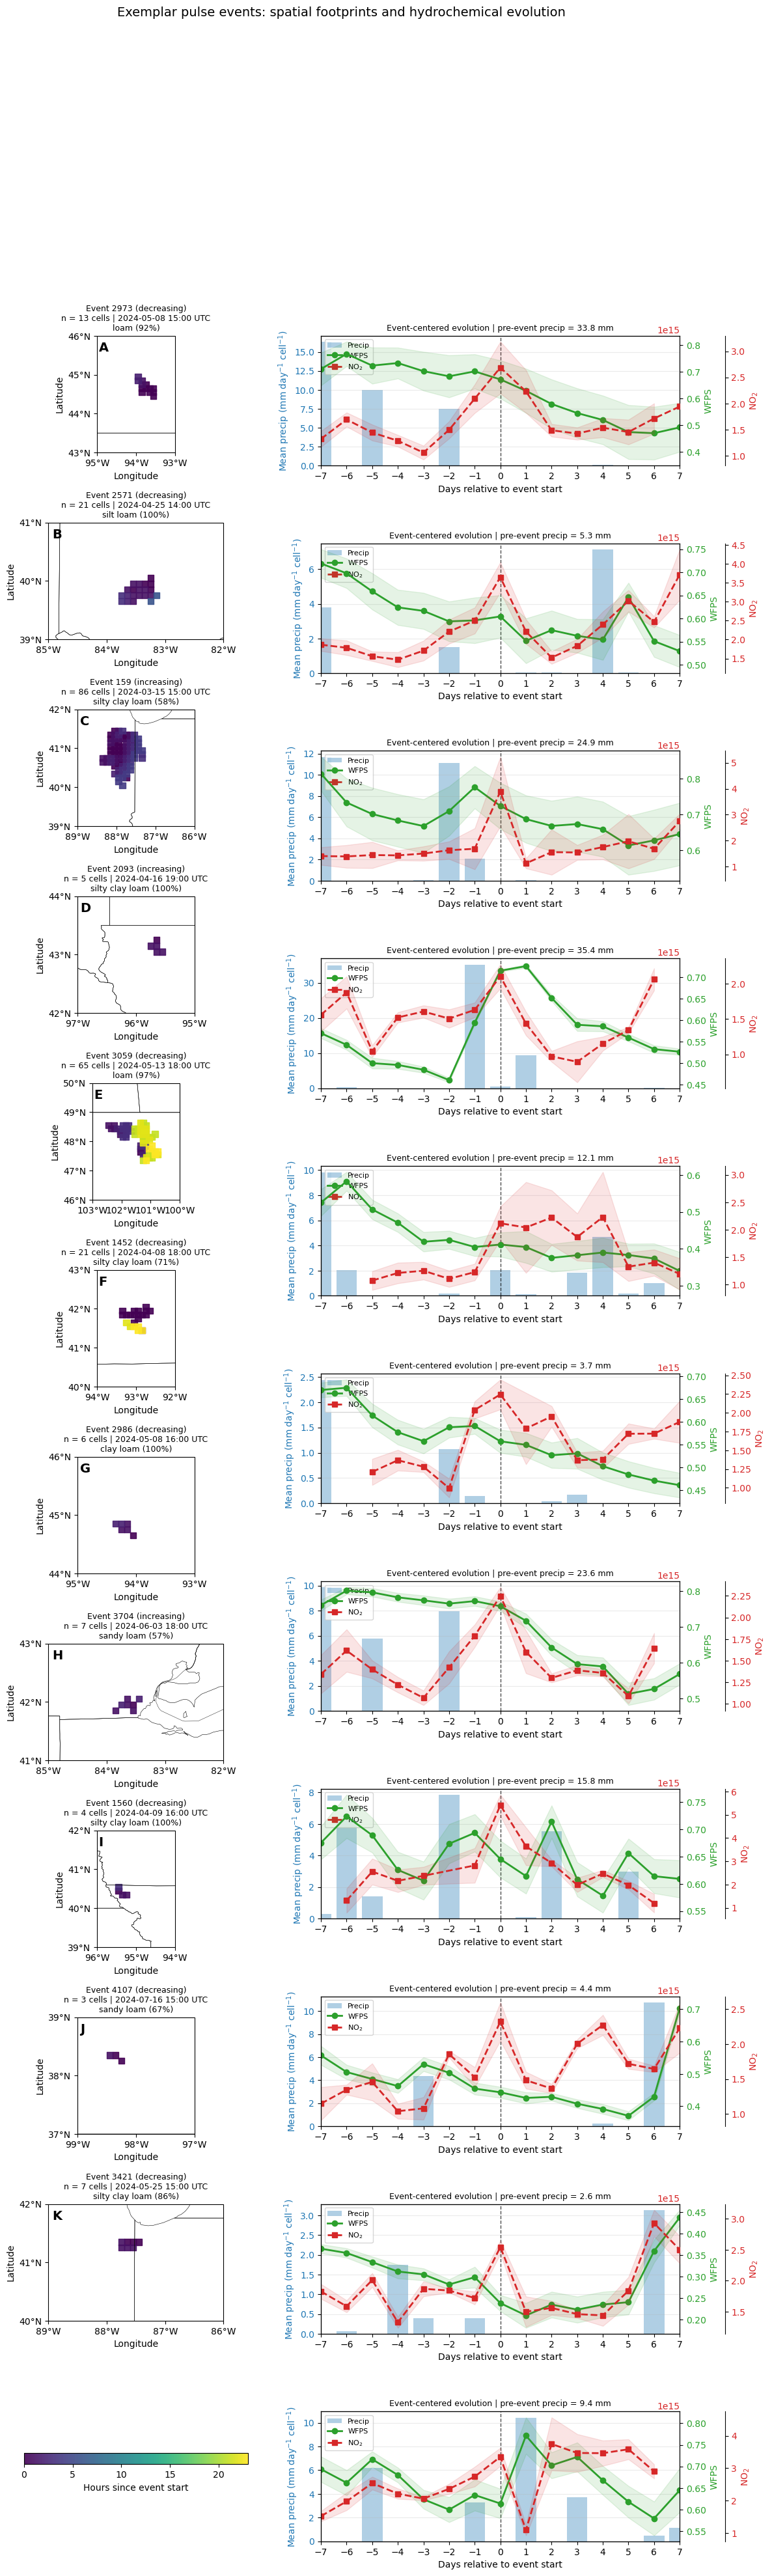

In [15]:
events_to_plot = exemplars['group_id'].head(11).tolist() if len(exemplars) > 0 else pulse_df['group_id'].value_counts().head(11).index.tolist()

_pulse_for_sm = pulse_df.dropna(subset=["sm_class"])
_event_sm_counts = (_pulse_for_sm.groupby(["group_id", "sm_class"]).size().unstack(fill_value=0))
event_sm_frac = _event_sm_counts.div(_event_sm_counts.sum(axis=1), axis=0)
if len(event_sm_frac) > 0:
    event_sm_frac["dominant_class"] = event_sm_frac.idxmax(axis=1)

window_days = 7
panel_labels = [f"{letter}{num if num > 0 else ''}"
                for num in range(10)
for letter in string.ascii_uppercase]

#data preparation
df = df.copy()
pulse_df = pulse_df.copy()

df["datetime"] = pd.to_datetime(df["datetime"])
pulse_df["datetime"] =pd.to_datetime(pulse_df["datetime"])

events_to_plot = [
    eid for eid in events_to_plot
    if eid in pulse_df["group_id"].unique()]

n_events = len(events_to_plot)

#figure setup
fig = plt.figure(figsize=(13, 4 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.6)
map_axes = []
last_sc = None

#color range for hours since start
all_event_pulses = pulse_df[pulse_df["group_id"].isin(events_to_plot)].copy()
all_event_pulses["hours_since_start"] = (all_event_pulses["datetime"] - all_event_pulses.groupby("group_id")["datetime"]
                                         .transform("min")).dt.total_seconds() / 3600

vmin_time = 0
vmax_time = all_event_pulses["hours_since_start"].max()

#loop through events
for row, eid in enumerate(events_to_plot):

    inner = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[row], width_ratios=[1.0, 1.6], wspace=0.25)

    #event data
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells =event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 =event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = ((event_pulses["datetime"] -t0).dt.total_seconds() /3600)

    #soil texture 
    if "dominant_texture" in event_pulses.columns:
        event_soils = (event_pulses[["grid_lat", "grid_lon", "dominant_texture"]] 
                       .drop_duplicates(subset=["grid_lat", "grid_lon"])
                       .dropna(subset=["dominant_texture"]))

        if len(event_soils) >0:
            soil_counts = event_soils["dominant_texture"].value_counts()
            dominant_soil =soil_counts.index[0]
            dominant_soil_frac = soil_counts.iloc[0] / soil_counts.sum()
            soil_str =f"{dominant_soil} ({dominant_soil_frac:.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    #sm class
    try:
        sm_label = event_sm_frac.loc[eid, "dominant_class"]
    except Exception:
        sm_label ="Unknown"

    #window time series 
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()

    sub =sub[(sub["datetime"] >= t0 - pd.Timedelta(days=window_days)) & 
    (sub["datetime"] <= t0 + pd.Timedelta(days=window_days))].copy()

    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() /86400.0).astype(int)

    #daily aggregate per cell 
    agg_cell = {"precip": ("h_precip_mm", "sum"),
                "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = (sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index())

    #aggregate across event cells 
    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"),
                 "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"]= ("wfps", "std")
    event_daily = (cell_daily.groupby("lag_day").agg(**agg_event).reset_index())

    #add missing lag days
    full_lags = pd.DataFrame({"lag_day": np.arange(-window_days, window_days + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily["precip_mean"] = event_daily["precip_mean"].fillna(0)
    event_daily["precip_std"] = event_daily["precip_std"].fillna(0)

    #left panel is the map
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)

    sc = ax_map.scatter(event_pulses["grid_lon"], event_pulses["grid_lat"], c=event_pulses["hours_since_start"],
                        cmap="viridis", vmin=vmin_time, vmax=vmax_time, s=45, marker="s", alpha=0.9, 
                        transform=ccrs.PlateCarree())

    last_sc = sc
    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)
    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")
    ax_map.text( 0.02, 0.95, panel_labels[row], transform=ax_map.transAxes, fontsize=14, fontweight="bold",
                va="top", ha="left")

    title = ( f"Event {eid} ({sm_label})\n"
             f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC")

    if soil_str:
        title += f"\n{soil_str}"

    ax_map.set_title(title, fontsize=9)

    #right panel is the time series
    ax_ts = fig.add_subplot(inner[1])

    ax_ts.bar( event_daily["lag_day"], event_daily["precip_mean"], color="tab:blue", alpha=0.35, width=0.8, 
              label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    #wfps axis 
    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()

        valid_wfps = event_daily["wfps_mean"].notna()

        ax_wfps.plot(event_daily.loc[valid_wfps, "lag_day"], event_daily.loc[valid_wfps, "wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")

        ax_wfps.fill_between(event_daily.loc[valid_wfps, "lag_day"],
                             (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[valid_wfps],
                             (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[valid_wfps],
                             color="tab:green",alpha=0.12)

        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    #no2 axis
    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))

    valid_no2 = event_daily["no2_mean"].notna()

    ax_no2.plot(event_daily.loc[valid_no2, "lag_day"], event_daily.loc[valid_no2, "no2_mean"],
                color="tab:red", linestyle="--",marker="s",linewidth=2, label="NO$_2$")

    ax_no2.fill_between(event_daily.loc[valid_no2, "lag_day"],
                        (event_daily["no2_mean"] - event_daily["no2_std"]).loc[valid_no2],
                        (event_daily["no2_mean"] + event_daily["no2_std"]).loc[valid_no2],
                        color="tab:red", alpha=0.12)

    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")
    ax_ts.set_xlim(-window_days, window_days)
    ax_ts.set_xticks(np.arange(-window_days, window_days + 1, 1))
    ax_ts.set_xlabel("Days relative to event start")

    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()

    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm", fontsize=9)

    #legend 
    handles = [Patch(facecolor="tab:blue", alpha=0.35, label="Precip"), Line2D([0], [0], color="tab:red", linestyle="--",
                                                                               marker="s", linewidth=2, label="NO$_2$")]

    if has_wfps:
        handles.insert(1, Line2D([0], [0], color="tab:green", marker="o", linewidth=2, label="WFPS"))

    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

#colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0.02, 1, 0.99])
#plt.savefig("exemplar_events.png",dpi=150, bbox_inches="tight")
plt.show()

# Temporal and spatial plots 

In [16]:
event_summary = (pulse_df.groupby("group_id").agg(
    n_cells=("grid_lat", "count"),
    mean_no2=("no2_mean", "mean"),
    max_no2=("no2_mean", "max"),
    std_no2=("no2_mean", "std"),
    start_time=("datetime", "min"),
    start_hour_local=("local_hour", "min"),
    duration_hours=("datetime", lambda x: (x.max() - x.min()).total_seconds()/3600),
    mean_precip=("h_precip_mm", "mean"),
).reset_index())

In [17]:
event_summary

,group_id,n_cells,mean_no2,max_no2,std_no2,start_time,start_hour_local,duration_hours,mean_precip
0,0,1,1.799002e+15,1.799002e+15,NaN,2024-03-11 15:00:00,10,0.0,0.000
1,2,1,2.611735e+15,2.611735e+15,NaN,2024-03-11 15:00:00,10,0.0,NaN
2,3,1,2.515861e+15,2.515861e+15,NaN,2024-03-11 15:00:00,10,0.0,0.000
3,4,1,3.518118e+15,3.518118e+15,NaN,2024-03-11 16:00:00,11,0.0,0.000
4,5,2,2.467023e+15,2.549638e+15,1.168359e+14,2024-03-11 15:00:00,10,1.0,0.000
...,...,...,...,...,...,...,...,...,...
1302,4390,1,2.730226e+15,2.730226e+15,NaN,2024-07-31 16:00:00,10,0.0,0.305
1303,4392,2,2.796761e+15,3.261839e+15,6.577201e+14,2024-07-31 17:00:00,12,0.0,0.000
1304,4393,1,3.110484e+15,3.110484e+15,NaN,2024-07-31 17:00:00,12,0.0,0.000
1305,4394,1,2.429247e+15,2.429247e+15,NaN,2024-07-31 17:00:00,12,0.0,0.000


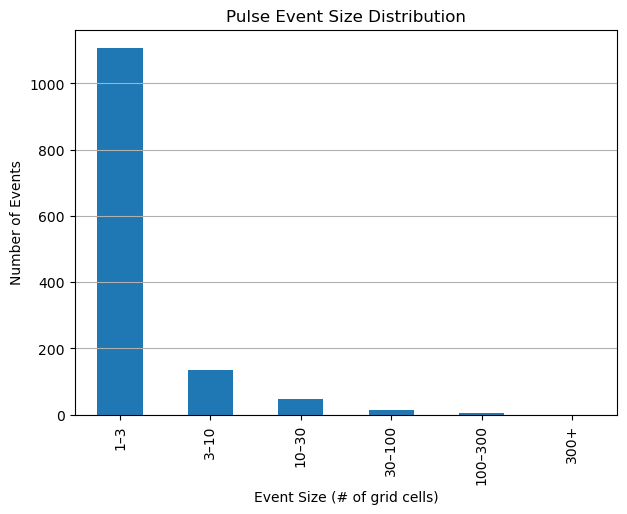

In [18]:
event_summary["size_bin"] = pd.cut(
    event_summary["n_cells"],
    bins=[0, 3, 10, 30, 100, 300, 1000],
    labels=["1–3", "3–10", "10–30", "30–100", "100–300", "300+"])

size_counts = (event_summary["size_bin"].value_counts().sort_index())
plt.figure(figsize=(7,5))

size_counts.plot(kind="bar")

plt.xlabel("Event Size (# of grid cells)")
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution")

plt.grid(axis="y")
plt.show()

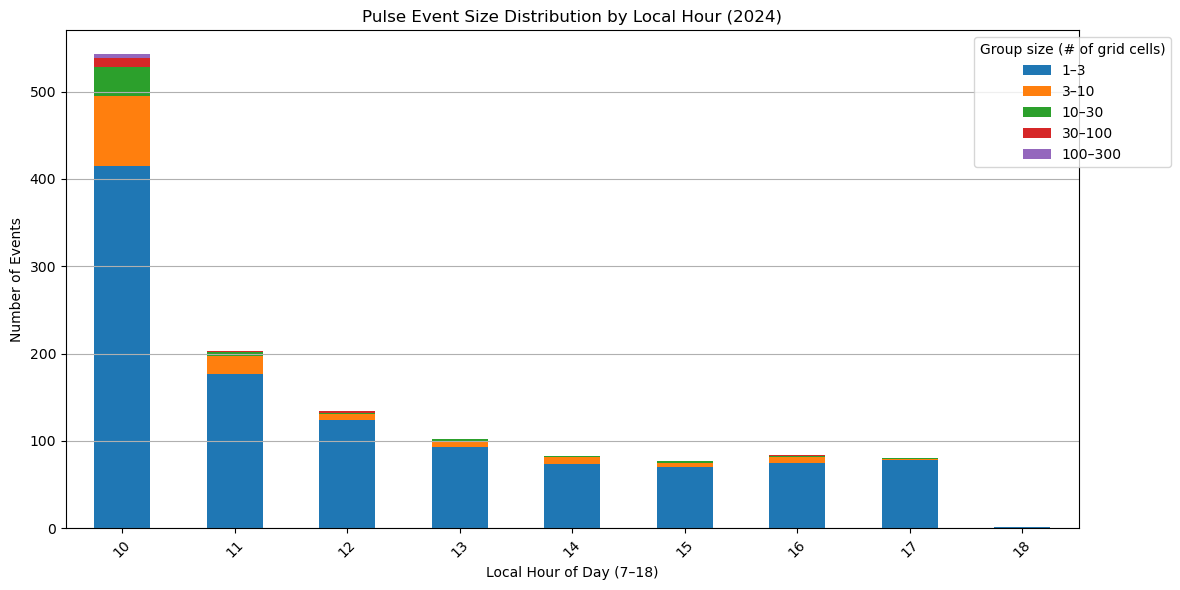

In [19]:
counts = (event_summary.groupby(["start_hour_local", "size_bin"], observed=True).size()
          .unstack(fill_value=0))

#only want 7-18 hours
counts = counts.loc[7:18]

counts.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.xlabel("Local Hour of Day (7–18)")
plt.xticks(rotation=45)
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution by Local Hour (2024)")

plt.legend(title="Group size (# of grid cells)", bbox_to_anchor=(0.89, 1), loc="upper left")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

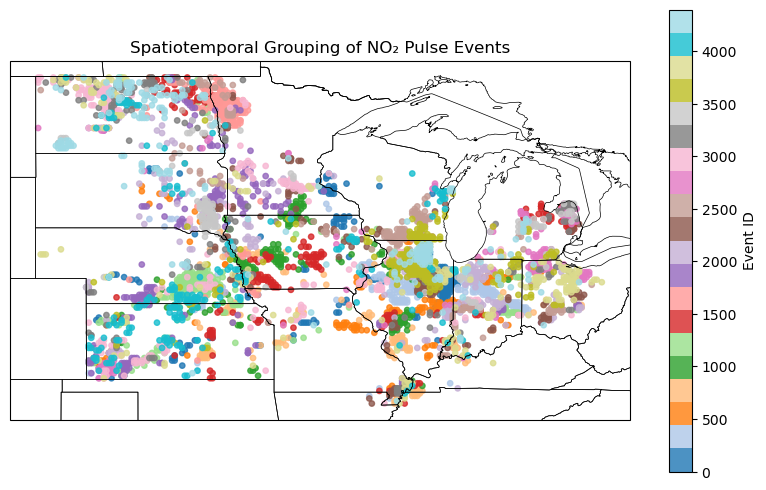

In [20]:
plot_df = pulse_df.copy()

fig = plt.figure(figsize=(10,6))
ax =plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.coastlines()

# scatter colored by group_id
sc = ax.scatter(plot_df["grid_lon"], plot_df["grid_lat"], c=plot_df["group_id"], cmap="tab20",
                s=15, alpha=0.8, transform=ccrs.PlateCarree())

plt.colorbar(sc, ax=ax, label="Event ID")
ax.set_title("Spatiotemporal Grouping of NO₂ Pulse Events")
plt.show()

In [21]:
n_pulses = len(pulse_df)
n_events = pulse_df["group_id"].nunique()

print("Individual pulses:", n_pulses)
print("Grouped events:", n_events)

Individual pulses: 4396
Grouped events: 1307


In [22]:
reduction_factor = n_pulses / n_events

print("Reduction factor:", reduction_factor)

Reduction factor: 3.3634276970160673


# are grouped events correlated with soil moisture changes?

In [23]:
pulse_df = pulse_df.dropna(subset=["sm_class"])

In [24]:
event_sm_counts = (pulse_df.groupby(["group_id", "sm_class"]).size().unstack(fill_value=0))
event_sm_frac = event_sm_counts.div(event_sm_counts.sum(axis=1), axis=0)

In [25]:
threshold = 0.7
numeric_cols = event_sm_counts.columns  #"Increasing" or "Decreasing"

event_sm_frac["dominant_class"] = event_sm_frac[numeric_cols].idxmax(axis=1)
event_sm_frac["dominant_frac"] =event_sm_frac[numeric_cols].max(axis=1)

event_sm_frac["coherent"] =event_sm_frac["dominant_frac"] >=threshold

In [26]:
n_events = len(event_sm_frac)
n_coherent = event_sm_frac["coherent"].sum()

print("Total events:", n_events)
print("Coherent events:", n_coherent)
print("Fraction coherent:", n_coherent / n_events)

Total events: 1307
Coherent events: 1269
Fraction coherent: 0.9709257842387146


In [27]:
coherent_events = event_sm_frac[event_sm_frac["coherent"]]

print(coherent_events["dominant_class"].value_counts())

dominant_class
decreasing    834
increasing    434
no data         1
Name: count, dtype: int64


In [28]:
event_sizes = pulse_df.groupby("group_id").size().rename("event_size")

plot_df = event_sm_frac.copy()
plot_df = plot_df.merge(event_sizes, left_index=True, right_index=True)


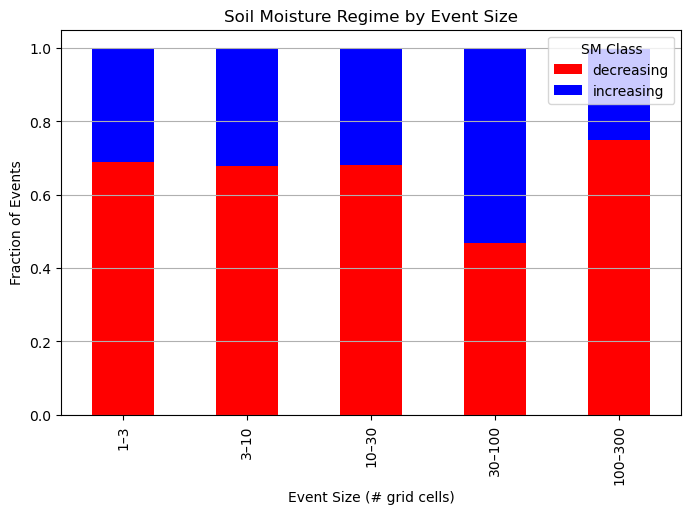

In [29]:
plot_df["size_bin"] = pd.cut(
    plot_df["event_size"],
    bins=[1, 3, 10, 30, 100, 300, 1000],
    labels=["1–3", "3–10", "10–30", "30–100", "100–300", "300+"])
size_sm_counts = (plot_df.groupby(["size_bin", "dominant_class"]).size().unstack(fill_value=0))
size_sm_frac = size_sm_counts.div(size_sm_counts.sum(axis=1), axis=0)

size_sm_frac.plot( kind="bar", stacked=True, figsize=(8,5), color=["red", "blue"])
plt.xlabel("Event Size (# grid cells)")
plt.ylabel("Fraction of Events")
plt.title("Soil Moisture Regime by Event Size")

plt.legend(title="SM Class")
plt.grid(axis="y")
plt.show()

In [30]:
cells = pulse_df.drop_duplicates(["group_id", "grid_lat", "grid_lon"])     # each cell once per event
lat = np.deg2rad(cells["grid_lat"].to_numpy())
cells = cells.assign(area_km2=6371.0088**2 * np.deg2rad(0.1) *
                     (np.sin(lat + np.deg2rad(0.05)) - np.sin(lat - np.deg2rad(0.05))))   # area of each 0.1° cell

event_area = cells.groupby("group_id")["area_km2"].sum()

print(f"Mean event area:{event_area.mean():,.0f} km²")
print(f"Median event area:{event_area.median():,.0f} km²")
print(f"Max event area:{event_area.max():,.0f} km²")
print(f"Min event area:{event_area.min():,.0f} km²")
print(event_area.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(0))

Mean event area:302 km²
Median event area:96 km²
Max event area:11,684 km²
Min event area:81 km²
count     1307.0
mean       302.0
std        843.0
min         81.0
25%         91.0
50%         96.0
75%        193.0
90%        491.0
max      11684.0
Name: area_km2, dtype: float64
